# Математички методи за машинско учење 2025/2026

## Домаћи задатак број 3

<div class="alert alert-block alert-danger">
<b>Име и презиме студента:</b> Jovan Paunović

<b>Број индекса:</b> 2122
    
</div>    

<div class="alert alert-block alert-info">
<b>Упутство за израду и предају домаћег задатака: </b> 
    
    1. Пре почетка израде промените име датотеке у 03Domaci_Ime_Prezime. (убаците своје име и презиме) 
    2. Попуните ћелију испод наслова одговарајућим подацима. 
    1. Употреба ћирилице није обавезна за предају домаћег задатка.
    4. За решавање задатака, уколико је потребно, отворите испод текста задатка додатне ћелије за уписивање текстуалног одговора (Markdown) или програмског кода (Code).
    1. Сва израчунавања, уколико је потребно, вршити у Python-у.
    5. Након завршетка израде решења домаћег Notebook документ сачувати у pdf формату и проследити га наставнику. То можете да урадите или кроз Teams или на мејл адресу jovana.dzunic@elfak.ni.ac.rs

</div> 

In [1]:
import numpy as np
import numpy.random as rndm
import matplotlib as mplb
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.datasets import make_blobs

**Задатак 1.** У стандардном  K-means алгоритму, сваки податак припада искључиво једном кластеру. Нека је дат скуп података $X\in\mathbb{R}^{d\times N}$ где је $d$ димензија података, а $N$ број података (подаци су колоне матрице $X$). Нека је $K$ број жељених кластера. Циљ K-means алгоритма је минимизација функције инерције $$inercija=\sum_{i=1}^K\sum_{x_j\in C_i}\|x_j-c_i\|^2.$$ 
Корак ажурирања центара може да се запише у матричној форми. Најпре уводимо матрице које у том изразу учествују.

Нека је $H\in\{0,1\}^{K\times N}$ тзв. индикаторска матрица - бинарна матрица која за сваки податак бележи да ли је елемент кластера,
$$H(i,j)=\begin{cases}1,& i-{\rm том\ кластеру\ припада\ } j-{\rm ти\ податак}\\
0,& {\rm иначе}\end{cases}$$

**а)** Нека је $C\in\mathbb{R}^{d\times K}$ матрица чије колоне чувају координате центара $c_i$ кластера $C_i.$ У новој итерацији дошло је до прерасподеле података по кластерима, то је садржај ажуриране матрице $H.$ Анализирати структуру матрице $M=HH^T:$ Да ли је она пуна, дијагонална или блок матрица? Шта представљају елементи на њеној дијагонали а шта су вандијагонални елементи?

(5 поена)

In [2]:
# KxN, K=4 klastera, N=10 podataka
# primer matrice H
H = np.array([[1,0,1,0,0,1,0,0,0,0],
              [0,1,0,0,0,0,1,0,0,0],
              [0,0,0,1,0,0,0,1,1,0],
              [0,0,0,0,1,0,0,0,0,1]])

print(H.T)

M=H@H.T
M

[[1 0 0 0]
 [0 1 0 0]
 [1 0 0 0]
 [0 0 1 0]
 [0 0 0 1]
 [1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 1 0]
 [0 0 0 1]]


array([[3, 0, 0, 0],
       [0, 2, 0, 0],
       [0, 0, 3, 0],
       [0, 0, 0, 2]])

Matrica $M$ je dijagonalna matrica dimenzija $K\times K$. Njeni dijagonalni elementi predstavljaju brojeve elemenata po klasterima. Element $M_{i,i}$ predstavlja broj elemenata u $i$-tom klasteru. Vandijagonalni elementi su uvek $0$, zato što jedan element pripada isključivo jednom klasteru, odnosno u matrici $H$ u jednoj koloni postoji samo jedna jedinica. Zbog toga kad se računa $HH^T$ vandijagonalni elementi ispadaju nule.

**б)** Потребно је одредити нове центре кластера као центре скупа вектора по кластерима. 
Показати (извођењем или образложењем) да се координате нових центара кластера могу добити решавањем матричне једначине по $C:$
$$C(HH^T)=XH^T\quad\iff\quad CM=XH^T.$$

(5 поена)

Novi centar klastera predstavlja centar skupa vektora u tom klasteru:
$$c_i=\frac{1}{n_i}\sum _{x_j\in C_i}x_j \quad (1)$$

pri čemu je $n_i$ broj vektora u $i$-tom klasteru.

Matrica $XH^T$ u $i$-toj koloni ima zbir svih vektora koji pripadaju klasteru $C_i$.

Formulu za izračunavanje centra klastera možemo da zapišemo kao $$n_i c_i = \sum _{x_j\in C_i}x_j \quad (2)$$

Dakle, na desnoj strani imamo zbir koji odgovara $i$-toj koloni matrice $XH^T$.

Na levoj strani imamo matricu centara klastera koja se množi matricom $M$ kod koje element $M_{i,i}=n_i$ predstavlja broj elemenata u klasteru $C_i$.
Rezultat ovog proizvoda je matrica dimenzija $d\times K$ (što se poklapa sa dimenzijama matrice $XH^T$), koja u $i$-toj koloni sadrži proizvod $n_i c_i$, što je na osnovu formule $(2)$ zapravo jednako sumi vektora koji pripadaju klasteru $C_i$, a to je upravo $i$-ta kolona matrice $XH^T$. Odatle zaključujemo da važi jednakost $$CM=XH^T$$
Kako bismo odredili matricu $C$ odnosno nove centre klastera, potrebno je rešiti ovu matričnu jednačinu po $C$. To se postiže sledećim izrazom:
$$C=XH^TM^{-1}$$ Bitno je napomenuti da matrica $M$ ima inverznu matricu samo ukoliko svaki klaster ima bar po jedan element.

Ovo ćemo proveriti sledećim Python kodom:

In [3]:
# d=2, N=4
X = np.array([[1, 2, 0, 0],
              [0, 0, 2, 3]])

# prvi klaster ima 3 elementa, drugi ima 1
H = np.array([[1, 1, 1, 0],
              [0, 0, 0, 1]])

M = H @ H.T
XHT = X @ H.T

M_inv = np.linalg.inv(M)

C = XHT @ M_inv

# racunamo centre rucno radi provere
cluster1 = X[:, 0:3]
cluster2 = X[:, 3:]
mean1 = np.mean(cluster1, axis=1)
mean2 = np.mean(cluster2, axis=1)

print("Matrica M = H H^T:\n", M)
print("Matrica X H^T:\n", XHT)
print("Matrica C\n", C)
print("Centar klastera 1 (očekivano):", mean1)
print("Centar klastera 2 (očekivano):", mean2)

Matrica M = H H^T:
 [[3 0]
 [0 1]]
Matrica X H^T:
 [[3 0]
 [2 3]]
Matrica C
 [[1.         0.        ]
 [0.66666667 3.        ]]
Centar klastera 1 (očekivano): [1.         0.66666667]
Centar klastera 2 (očekivano): [0. 3.]


Možemo zaključiti da se dobijeni rezultati slažu, što potvrđuje činjenicu da se novi centri klastera, odnosno matrica $C$ može odrediti na ranije opisani način.

**в)** У напреднијим алгоритмима кластеризације (нпр. *Gaussian Mixture Models* или *Fuzzy C-means*) информације о припадности кластеру нису "црно-беле" већ носе опис могућности припадања једног податка свим кластерима. То се најчешће изражава вероватноћом припадности елемента кластерима. Индикаторска матрица је сада $H\in[0,1]^{K\times N}$ са својством да је збир елемената дуж сваке колоне једнак $1,$
$$H(i,j)={\rm вероватноћа\ да\ }j-{\rm ти\ податак\ припада\ }i-{\rm том\ кластеру}\in[0,1].$$
$$\displaystyle\sum_{i=1}^K H_{ij} = 1{\ \rm за\ свако\ }j$$
*$[0,1]$ је сегмент са реалне праве, $\{0,1\}$ је двоелементни скуп!*

Претпоставка је да ниједан од кластера није без елемената, тј. да су вероватноће свих елемената за њега једнаке $0.$

Анализирати структуру матрице $M=HH^T:$ Да ли је она пуна, дијагонална или блок матрица? Шта представљају елементи на њеној дијагонали а шта су вандијагонални елементи?

(5 поена)

In [4]:
# KxN, K=4 klastera, N=10 podataka
# primer matrice H
H = np.array([[0.8, 0.1, 0.7, 0.2, 0.0, 0.9, 0.1, 0.2, 0.3, 0.0],
              [0.1, 0.7, 0.1, 0.1, 0.0, 0.05, 0.8, 0.1, 0.2, 0.0],
              [0.05, 0.1, 0.1, 0.6, 0.1, 0.02, 0.05, 0.6, 0.4, 0.2],
              [0.05, 0.1, 0.1, 0.1, 0.9, 0.03, 0.05, 0.1, 0.1, 0.8]])

print(H.T)

M=H@H.T
M

[[0.8  0.1  0.05 0.05]
 [0.1  0.7  0.1  0.1 ]
 [0.7  0.1  0.1  0.1 ]
 [0.2  0.1  0.6  0.1 ]
 [0.   0.   0.1  0.9 ]
 [0.9  0.05 0.02 0.03]
 [0.1  0.8  0.05 0.05]
 [0.2  0.1  0.6  0.1 ]
 [0.3  0.2  0.4  0.1 ]
 [0.   0.   0.2  0.8 ]]


array([[2.13  , 0.445 , 0.503 , 0.222 ],
       [0.445 , 1.2125, 0.326 , 0.1665],
       [0.503 , 0.326 , 0.9554, 0.4356],
       [0.222 , 0.1665, 0.4356, 1.5059]])

Matrica $M$ je sada puna, a ne dijagonalna kao u delu pod $(a)$. Takođe je i simetrična.

Dijagonalni elementi $M_{i,i}$ su definisani na sledeći način:
$$
M_{i,i} = \sum_{j=1}^N H(i,j)^2
$$

To je zbir kvadrata verovatnoća da svaki podatak pripada klasteru $i$. Praktično, što su veće verovatnoće pripadnosti podataka klasteru $i$, to je ovaj zbir veći, pa može da se tumači kao neka veličina klastera, pri čemu ne daje jasno definisan broj elemenata u klasteru.

Vandijagonalni elementi $M_{p,q}, \; p \neq q$ su definisani na sledeći način:
$$
M_{p,q} = \sum_{j=1}^N H(p,j)\,H(q,j)
$$
Praktično se računa skalarni proizvod između vrsta $p$ i $q$ u matrici $H$. Ovi elementi pokazuju koliko su klasteri $p$ i $q$ „slični“ u smislu da isti podaci imaju nenulte verovatnoće pripadnosti i jednom i drugom klasteru. Veliki su ako postoji veliki broj elemenata koji imaju značajne verovatnoće pripadnosti oba klastera $p$ i $q$. Ako su pripadnosti „stroge“ (kao u delu pod $(a)$), ovi elementi bi bili nula. Ali u ovom slučaju oni su pozitivni i pokazuju stepen preklapanja.

**г)** У овом типу класреовања израчунавање центара кластера више није проста аритметичка средина вектора из самог кластера већ тежинска средња вредност,
$$c_i=\dfrac{\displaystyle\sum_{j=1}^NH_{ij}x_j}{\displaystyle\sum_{j=1}^NH_{ij}}.$$
Уводи се дијагонална матрица тежина:
$$
D = \mathrm{diag}\Big(\sum_{j}H_{1j},\dots,\sum_{j}H_{Kj}\Big),
$$


Показати (извођењем или образложењем) да се координате нових центара кластера могу и сада добити решавањем матричне једначине по $C:$
$$CD=XH^T.$$

(5 поена)

Formula za računanje težinske srednje vrednosti praktično znači da svaki podatak $x_j$ doprinosi centru klastera $c_i$ proporcionalno svojoj verovatnoći $H_{ij}$ da pripada tom klasteru.

Element $D_{i,i}$ matrice $D$ predstavlja sumu verovatnoća pripadnosti podataka klasteru $i$. To je praktično imenilac u formuli za računanje težinske srednje vrednosti. Analogno delu pod $(a)$, formulu za računanje težinske srednje vrednosti možemo da zapišemo i na sledeći način:

$$
c_i \cdot \left( \sum_{j=1}^N H_{ij} \right) = \sum_{j=1}^N H_{ij} x_j
$$

Sada posmatramo matricu proizvoda $XH^T$. Njena $i$-ta kolona je:

$$
(XH^T)_{:,i} = \sum_{j=1}^N x_j H_{ij}
$$

što je zapravo brojilac iz formule za računanje težinske srednje vrednosti, odnosno predstavlja težinski zbir vektora za klaster $i$ (svaki vektor iz skupa podataka pomnožen verovatnoćom da pripada klasteru $i$, pa sve sabrano).

S obzirom na to da je:
$$
D = \mathrm{diag}\Big(\sum_{j}H_{1j},\dots,\sum_{j}H_{Kj}\Big),
$$

onda izraz
$$
c_i \cdot \left( \sum_{j=1}^N H_{ij} \right)
$$

može matrično da se zapiše kao $CD$.

Zbog svega toga važi sledeća jednačina:

$$
CD = XH^T
$$

jer se po kolonama dobija:

$$
c_i \cdot D_{ii} = \sum_{j=1}^N x_j H_{ij}
$$

Rešavanjem po matrici $C$, dobijamo:

$$
C = X H^T D^{-1}
$$

što znači da se centri klastera dobijaju kao težinske srednje vrednosti, u skladu sa verovatnoćama pripadnosti.

Takođe, kao i u delu $(a)$, možemo ovo proveriti sledećim Python kodom:

In [5]:
# d=2, N=4
X = np.array([[1, 2, 0, 0],
              [0, 0, 2, 3]])

# matrica H sada sadrži verovatnoće pripadnosti klasterima
H = np.array([[0.8, 0.6, 0.7, 0.2],
              [0.2, 0.4, 0.3, 0.8]])

D = np.diag(np.sum(H, axis=1))

XHT = X @ H.T

D_inv = np.linalg.inv(D)
C = XHT @ D_inv


weights1 = H[0, :]
weights2 = H[1, :]

# rucna provera
mean1 = (X @ weights1) / np.sum(weights1)
mean2 = (X @ weights2) / np.sum(weights2)

print("Matrica D:\n", D)
print("Matrica X H^T:\n", XHT)
print("Matrica C:\n", C)
print("Centar klastera 1 (očekivano):", mean1)
print("Centar klastera 2 (očekivano):", mean2)

Matrica D:
 [[2.3 0. ]
 [0.  1.7]]
Matrica X H^T:
 [[2. 1.]
 [2. 3.]]
Matrica C:
 [[0.86956522 0.58823529]
 [0.86956522 1.76470588]]
Centar klastera 1 (očekivano): [0.86956522 0.86956522]
Centar klastera 2 (očekivano): [0.58823529 1.76470588]


**д)** Сада је потребно да се симулира поступак кластеризације у коме се припадност тачака кластерима одређује преко **вероватноћа** према правилима описаним у претходном делу задатака. 

1. **Генерисање података**  
   Креирати 2D скуп података коришћењем функције `make_blobs`.  
   - Број кластера: 3  
   - Број тачака: 300  
   - Стандардна девијација кластера по избору  
   - Опционо: насумично seed ради репродуктивности резултат  
   
(2 поена)   

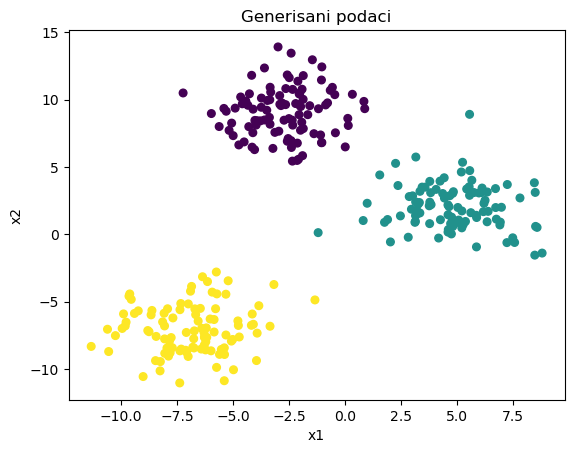

In [6]:
X, y_true = make_blobs(n_samples=300, n_features=2, centers=3, cluster_std=1.8, random_state=42)

plt.scatter(X[:, 0], X[:, 1], c=y_true, cmap='viridis', s=30)
plt.title("Generisani podaci")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

2. **Иницијализација матрице центара**  
   Иницијализовати матрицу центара  
  $$
   C^{(0)} \in \mathbb{R}^{2 \times 3}
  $$  
   насумичним избором три тачке из скупа података или униформно из опсега података.  
   
(3 поена)   

In [7]:
np.random.seed(42)
indices = np.random.choice(X.shape[0], size=3, replace=False)

C0 = X[indices].T

print("Inicijalna matrica centara:\n", C0)

Inicijalna matrica centara:
 [[ 3.57902227 -6.66309505  5.1456642 ]
 [ 3.50245346 -5.95411969  0.85231055]]


3. **Итеративно ажурирање (5 итерација)**  
   Извршити укупно **5 итерација** поступка.  

   У свакој итерацији:  
- Израчунавање матрице припадности

    Прво се израчуна привремена матрица $\tilde H^{(t)}$ према инверзним квадратима растојања (са малим $\varepsilon$ ради стабилности):
    $$
    \tilde H^{(t)}_{ij} \;=\; \frac{1}{\|x_j - c_i^{(t)}\|^2 + \varepsilon},\qquad
    \varepsilon=10^{-8}.
    $$
    Затим се нормализује по колонама да би свака колона имала збир једнак $1:$
    $$
       H^{(t)}_{ij} \;=\; \frac{\tilde H^{(t)}_{ij}}{\displaystyle\sum_{p=1}^K \tilde H^{(t)}_{pj}}.
    $$
    Ово гарантује да је $H^{(t)}\in[0,1]^{K\times N}$ и да важи
$$
\sum_{i=1}^K H^{(t)}_{ij}=1 \quad \text{за свако } j.
$$ 

- Ажурирајте матрицу центара коришћењем формуле:  
$$
     C^{(t+1)} = X {H^{(t)}}^T \left( H^{(t)} {H^{(t)}}^T \right)^{-1}.
$$

(5 поена)

In [8]:
if X.shape[0] != 2: # if obezbedjuje da se X samo jednom transponuje, ako izvrsavamo celiju vise puta
    X = X.T # prilagodjavanje oblika da se uklapa sa ranijim opisom tj. da bude dxN (2x300)
    
K = 3
N = X.shape[1] # 300
eps = 1e-8
C=C0.copy() # 2x3 tj. dxK

def do_iteration(C):
    # X.T[None, :, :] ima dimenzije (1,300,2)
    # C.T[:, None, :] ima dimenzije (3,1,2)
    # zbog broadcastinga, kad se oduzmu dobija se rezultat oblika (3, 300, 2) => (3 centra, 300 tacaka, 2 dimenzije)
    # racunamo normu duz trece ose, kvadriramo i dobijamo matricu D dimenzija (3, 300) => (3 centra, 300 podataka)
    # element Dij predstavlja udaljenost tacke j od centra klastera i
    D = np.linalg.norm(X.T[None,:,:] - C.T[:,None,:], axis=2)**2

    H_tilde = 1.0 / (D + eps)
    H = H_tilde / np.sum(H_tilde, axis=0)

    HHT_inv = np.linalg.inv(H @ H.T)
    C = X @ H.T @ HHT_inv

    return C, H

for t in range(5):
    C, _ = do_iteration(C)

    print(f"Iteracija {t+1} - Centri klastera:\n{C}\n")

Iteracija 1 - Centri klastera:
[[-0.96804232 -8.06262295  5.95022431]
 [11.12659036 -7.17527085  0.87621218]]

Iteracija 2 - Centri klastera:
[[-3.12488319 -7.56980677  5.8518515 ]
 [10.64279167 -7.80350772  1.55067384]]

Iteracija 3 - Centri klastera:
[[-3.19344844 -7.468128    5.70229603]
 [10.14548655 -7.83978226  1.79220975]]

Iteracija 4 - Centri klastera:
[[-3.1667244  -7.45374548  5.67385138]
 [ 9.99209044 -7.85529702  1.8186586 ]]

Iteracija 5 - Centri klastera:
[[-3.15183249 -7.45412029  5.67460996]
 [ 9.94655028 -7.86240904  1.81784544]]



4. **Приказ резултата**  
   - Након сваке итерације нацртати:  
     - тачке података у 2D равни,  
     - тренутно израчунате центре,  
     - боју тачака одредити према кластеру са највећом вероватноћом.  
   - По завршетку 5 итерација приказати завршне центре.  
   
(5 поена)   

Iteracija 1 - Centri klastera:
[[-0.96804232 -8.06262295  5.95022431]
 [11.12659036 -7.17527085  0.87621218]]



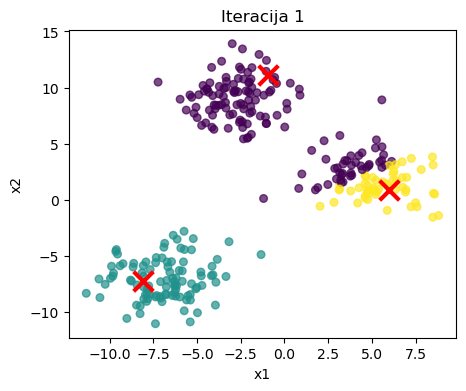

Iteracija 2 - Centri klastera:
[[-3.12488319 -7.56980677  5.8518515 ]
 [10.64279167 -7.80350772  1.55067384]]



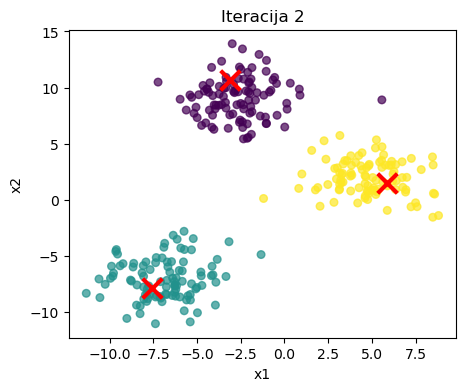

Iteracija 3 - Centri klastera:
[[-3.19344844 -7.468128    5.70229603]
 [10.14548655 -7.83978226  1.79220975]]



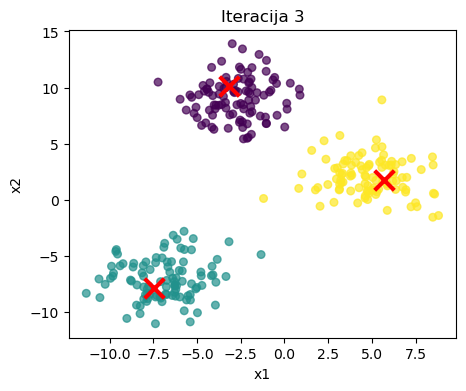

Iteracija 4 - Centri klastera:
[[-3.1667244  -7.45374548  5.67385138]
 [ 9.99209044 -7.85529702  1.8186586 ]]



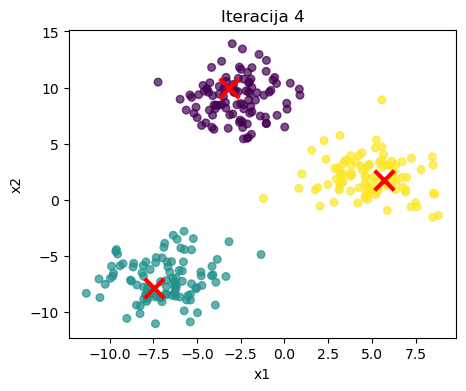

Iteracija 5 - Centri klastera:
[[-3.15183249 -7.45412029  5.67460996]
 [ 9.94655028 -7.86240904  1.81784544]]



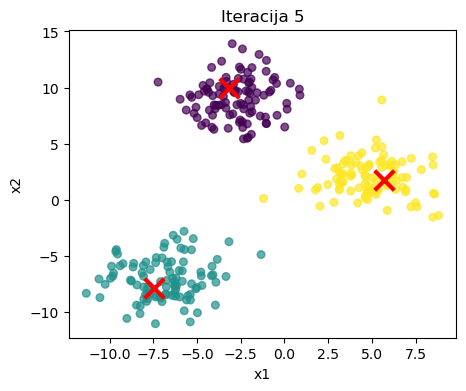

In [9]:
C=C0.copy()
for t in range(5):
    C, H = do_iteration(C)

    print(f"Iteracija {t+1} - Centri klastera:\n{C}\n")

    labels = np.argmax(H, axis=0)

    plt.figure(figsize=(5, 4))
    plt.scatter(X[0, :], X[1, :], c=labels, cmap='viridis', s=30, alpha=0.7)
    plt.scatter(C[0, :], C[1, :], c='red', marker='x', s=200, linewidths=3)
    plt.title(f"Iteracija {t+1}")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

C5 = C.copy()

5. **Конвергенција**

Након извршених 5 итерација, потребно је **додатно покренути алгоритам** све док се не испуни критеријум конвергенције:
$$
\max_i \| c_i^{(t+1)} - c_i^{(t)} \| < 10^{-4},
$$
или док се не достигне максималан број итерација (`max_iter = 500`).

Треба коментаристаи:
- укупан број итерација до конвергенције,
- да ли се положаји центара након првих 5 итерација значајно разликују од стања после конвергенције,
- кратак коментар о стабилности и понашању алгоритма; Да ли се центри брзо стабилизују? Да ли је алгоритам осетљив на почетне центре? Да ли су вероватноће понекад „превише меке“ или „превише оштре“? Да ли се центри "здраво" распоређују или склизну у неку регију? Да ли се међусобно приближавају?

(10 поена)

In [10]:
tol = 1e-4
max_iter = 500
iter_count = 5 # vec je izvrseno 5 iteracija

for t in range(max_iter - iter_count):
    C_new, H = do_iteration(C)

    if t==0:
        print("Matrica H u 6. iteraciji:\n", np.round(H,2))

    diff = np.linalg.norm(C_new - C, axis=0)

    C = C_new
    iter_count += 1

    if np.max(diff) < tol:
        print(f"Algoritam konvergirao posle ukupno {iter_count} iteracija.")
        break
else:
    print("Dostignut maksimalan broj iteracija bez konvergencije.")

print("Matrica H nakon poslednje iteracije:\n", np.round(H,2))
print("Konacni centri:\n", C)
print("Centri nakon 5. iteracije:\n", C5)
print("Razlika izmedju konacnih i centara nakon 5. iteracije:\n", C-C5)

Matrica H u 6. iteraciji:
 [[0.   0.   0.79 0.07 0.02 0.   0.99 0.01 0.98 0.98 0.96 0.01 0.72 0.94
  0.   0.97 0.02 0.21 0.99 0.91 0.81 1.   0.   0.   0.96 0.06 0.02 0.26
  0.02 0.93 0.95 0.99 0.01 0.85 0.06 0.97 0.01 0.01 0.   0.12 0.01 0.97
  0.   0.07 0.88 0.96 0.   0.03 0.   0.03 0.01 0.06 0.01 0.8  0.03 0.37
  0.01 0.93 0.02 0.99 0.03 0.06 0.01 0.12 0.03 0.08 0.05 0.01 0.02 0.99
  0.01 0.03 0.01 0.96 0.84 0.01 0.03 0.05 0.97 0.01 0.99 0.99 0.01 0.98
  0.01 0.01 0.03 0.82 0.03 0.9  0.03 0.97 0.02 0.94 1.   0.   0.01 0.99
  0.01 0.09 0.03 0.98 0.02 0.85 0.97 0.73 0.75 0.99 0.04 0.03 0.04 0.97
  0.96 0.83 0.89 0.01 0.01 0.29 0.02 0.08 0.07 0.   0.67 0.02 0.   0.
  0.03 1.   0.02 0.   0.92 0.93 0.73 0.91 0.91 0.02 0.04 0.   0.97 0.
  1.   0.94 0.13 0.97 0.12 0.07 0.01 0.98 0.01 0.99 0.85 0.05 0.01 0.05
  0.98 0.09 0.01 0.   0.02 0.99 0.89 0.01 0.04 0.02 0.88 0.01 0.03 0.92
  0.97 0.79 0.92 0.97 0.05 1.   0.09 0.02 0.   0.91 0.06 0.01 0.   0.99
  0.02 0.04 0.04 0.04 0.   0.83 0.25 0.03

**Komentari:**
- Ukupan broj iteracija za koje je algoritam konvergirao je 11 (računajući i prvih 5 izvršenih ranije). To je daleko manje od maksimalnih 500 iteracija, što znači da algoritam brzo konvergira.
- Položaji centara nakon 5. iteracije su veoma bliski položajima centara nakon konvergencije. Njihovim poređenjem vidimo da se oni razlikuju najčešće tek na trećoj decimali. Ovo znači da se centri relativno brzo stabilizuju, a dodatne iteracije uglavnom samo fino podešavaju pozicije centara.
- Algoritam se ponaša stabilno, odnosno centri se brzo stabilizuju i ne osciluju. Kao i ostale varijante K-means algoritma, i ovaj algoritam je osetljiv na izbor početnih centara, odnosno broj iteracija koji će biti potreban za konvergenciju algoritma zavisi od izbora početnih centara.
- Verovatnoće pripadnosti podataka klasterima su ponekad previše "oštre", a ponekad i previše "meke". Na primer, trenutno je standardna devijacija klastera u funkciji `make_blobs` postavljena na vrednost $1.8$, a sa nacrtanih plotova možemo da vidimo da su klasteri jasno odvojeni. Takođe, verovatnoće u matrici $H$ su oštre, odnosno jasno se može odrediti kom klasteru podatak pripada. Vrednosti verovatnoća su najčešće manje od $0.2$ ili veće od $0.8$. Praktično, ako su klasteri jasno razdvojeni, onda su i centri daleko, pa su i verovatnoće "oštre". Sa druge strane, postavljanjem standardne devijacije klastera na vrednost $3$ ili više, klasteri više nisu jasno odvojeni već se preklapaju. U tom slučaju, verovatnoće su više "meke", tj. može se desiti da neka tačka ima skoro podjednake verovatnoće pripadnosti različitim klasterima. 
- U normalnim uslovima, centri se raspoređuju "zdravo" oko gustih regiona tačaka i ne približavaju se previše jedan drugom, osim ako su početni centri veoma loše izabrani. U našem slučaju algoritam je dobro klasterizovao podatke.

***

**Здадатак 2.** K-means алгоритам је моћан и брз, али почива на одређеним геометријским претпоставкама. Овај задатак илуструје шта се дешава када се геометрија података не поклапа са метриком коју алгоритам користи.

Користићемо синтетички скуп података **"Two Moons"** који се састоји од два уланчана полумесеца. Ови подаци нису линеарно раздвојиви.

In [11]:
from sklearn.datasets import make_moons

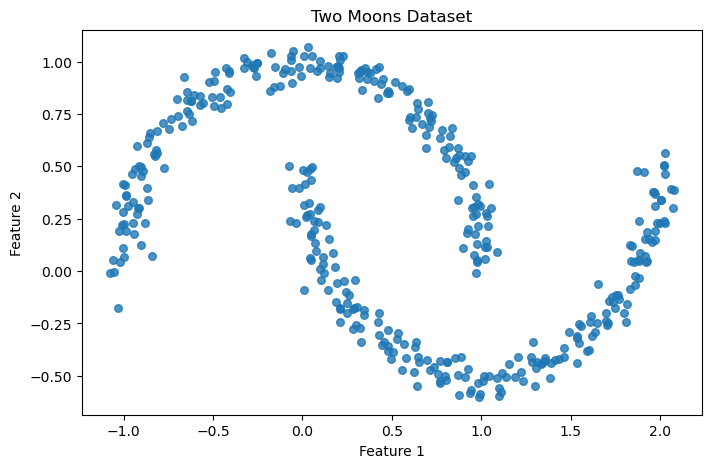

In [12]:
# Generisanje podataka
X_moons, y_moons = make_moons(n_samples=400, noise=0.05, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(X_moons[:,0], X_moons[:,1], s=30, alpha=0.8)
plt.title("Two Moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2");

**а)** Примена K-means алгоритма 

Применити K-means алгоритам са \(K=2\) над овим скупом података.  
Визуелизовати резултат на **Scatter plot-у**:  
- Обојити тачке различитим бојама у зависности од додељеног кластера.  
- Јасно означити положаје добијених центара (нпр. црвеним `'X'` маркером).  

(5 поена)

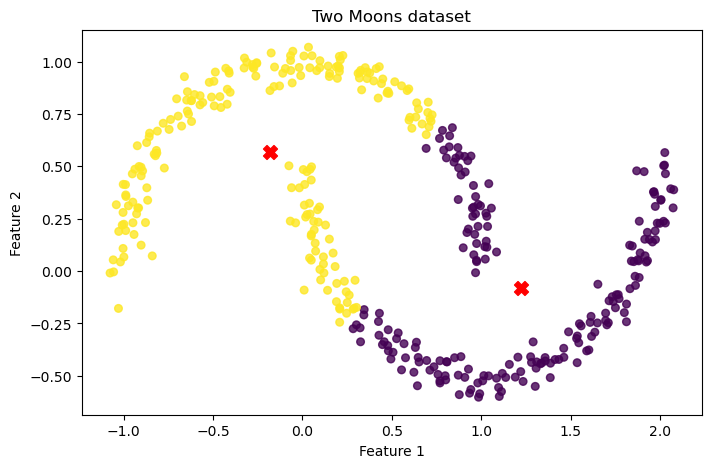

In [13]:
kmeans = KMeans(n_clusters=2, random_state=42)
labels = kmeans.fit_predict(X_moons)
centers = kmeans.cluster_centers_

plt.figure(figsize=(8, 5))
plt.scatter(X_moons[:,0], X_moons[:,1], c=labels, cmap='viridis', s=30, alpha=0.8)
plt.scatter(centers[:,0], centers[:,1], c='red', marker='X', s=100, linewidths=1)
plt.title("Two Moons dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**б)** 
Резултат који сте добили у претходном кораку вероватно није интуитивно исправан  
(кластери „секу“ природне облике полумесеца).  

Дајте математичко и геометријско објашњење овог феномена одговарајући на следећа питања:

#### Граница раздвајања кластера (граница одлучивања)
Граница између два кластера чине тачке $x$ које су подједнако удаљене од оба центра $c_1$ и $c_2.$  

Описано једначином:
$$
\|x - c_1\|^2 = \|x - c_2\|^2
$$

**Питање:** Шта геометријски представља ова једначина у $\mathbb{R}^2?$

(2 поена)

Ova jednačina predstavlja pravu u $\mathbb{R}^2$. Konkretno, ukoliko dva dobijena centra spojimo pomoću duži i nacrtamo pravu koja je normalna na ovu duž i deli je na dva jednaka dela, onda je ta prava sastavljena iz tačaka koje su na jednakoj udaljenosti od oba centra. Ta prava predstavlja granicu između dva klastera.

#### Закључак
Зашто K-means не може да раздвоји ова два полумесеца, без обзира на иницијализацију? Коју геометријску карактеристику показују кластери?

(3 поена)

K-means ne može da razdvoji ova dva polumeseca zato što je granica koju kreira u ovom slučaju prava linija, a podaci iz korišćenog dataseta nisu linearno separabilni u 2D, odnosno nemoguće je razdvojiti ih pravom linijom. Klasteri koji se dobijaju su konveksni, što i jeste odlika klastera dobijenih K-means algoritmom, stoga ovaj algoritam nije adekvatan za klasterizaciju odabranog skupa podataka (Two Moons).

**в)** Спектрално кластеровање као алтернатива (5 поена)

Проблем „месеца“ се решава променом простора у коме посматрамо податке или променом метрике.  

Иако ћемо математику иза овога (сопствене вредности Лапласијана графа) радити касније, овде демонстрирајте решење позивом готове функције.

(5 поена)

In [14]:
from sklearn.cluster import KMeans, SpectralClustering

C:\Users\jpaun\miniconda3\envs\faks\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


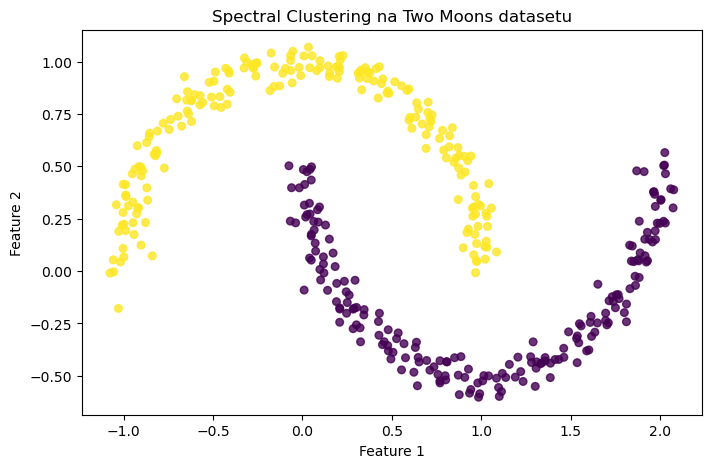

In [15]:
sc = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=52)
labels = sc.fit_predict(X_moons)

plt.figure(figsize=(8, 5))
plt.scatter(X_moons[:,0], X_moons[:,1], c=labels, cmap='viridis', s=30, alpha=0.8)
plt.title("Spectral Clustering na Two Moons datasetu")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

***

**Задатак 3.** Дат је скуп података који садржи информације о карактеристикама производа у продавници: цена производа, тежина производа и оцена корисника. Применом K-means алгоритма групишите производе у кластере. Одредите број кластера користећи мере квалитета кластеризације. 

(5 поена)

In [35]:
np.random.seed(42) # da bismo svaki put dobili iste rezultate
N=rndm.randint(200,450) #ukupan broj proizvoda
cena=rndm.normal(500,100,N)
tezina=rndm.normal(1000,200,N) #tezina u gramima
ocena=rndm.uniform(1,5,N)
podaci=np.block([[cena],[tezina],[ocena]]).T
podaci.shape

(302, 3)

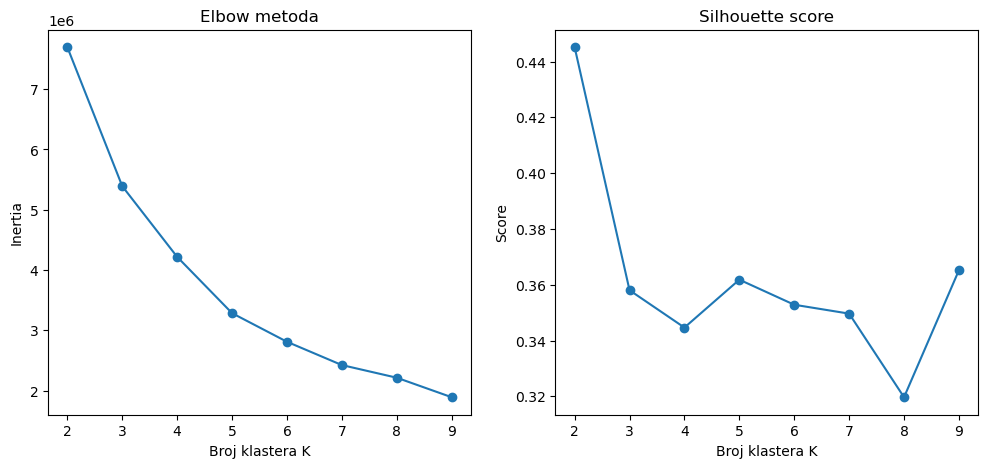

In [46]:
def execute_Kmeans(podaci):
    inertias = []
    sil_scores = []
    K_range = range(2, 10)
    labels_dict = {}
    
    for k in K_range:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(podaci)
        labels_dict[k] = labels
        inertias.append(km.inertia_)
        sil_scores.append(silhouette_score(podaci, labels))

    return inertias, sil_scores, K_range, labels_dict

def draw_elbow_and_silhouette(K_range, inertias, sil_scores):
    # Elbow metoda
    plt.figure(figsize=(12,5))
    plt.subplot(1,2,1)
    plt.plot(K_range, inertias, marker='o')
    plt.title("Elbow metoda")
    plt.xlabel("Broj klastera K")
    plt.ylabel("Inertia")
    
    # Silhouette score
    plt.subplot(1,2,2)
    plt.plot(K_range, sil_scores, marker='o')
    plt.title("Silhouette score")
    plt.xlabel("Broj klastera K")
    plt.ylabel("Score")
    plt.show()

inertias, sil_scores, K_range, labels_dict = execute_Kmeans(podaci)
draw_elbow_and_silhouette(K_range, inertias, sil_scores)

Sa prikazanih grafika vidimo da ...

За анализу добијених резултата кластеризације можете да користите графички приказ 3D или 2D. За 2D приказ користите парове карактеристика података. Нпр. оцена корисника у функцији цене производа и слично. Припадност различитим кластерима означавате различитим бојама тачака.

(5 поена)

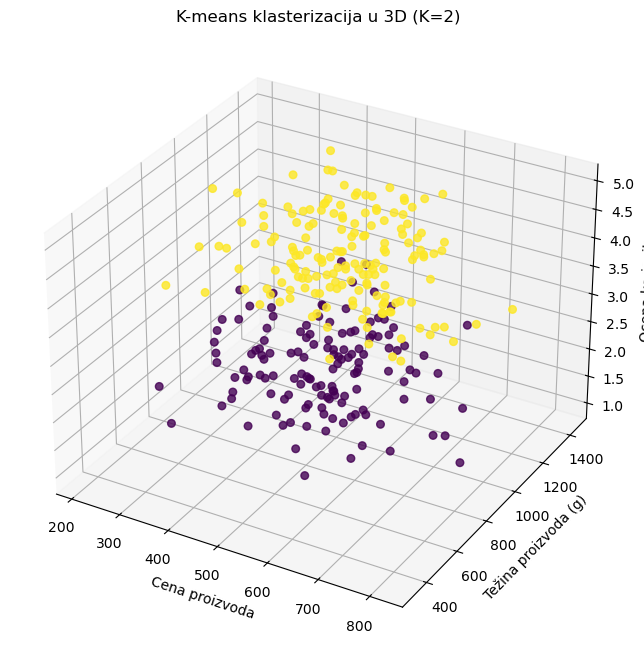

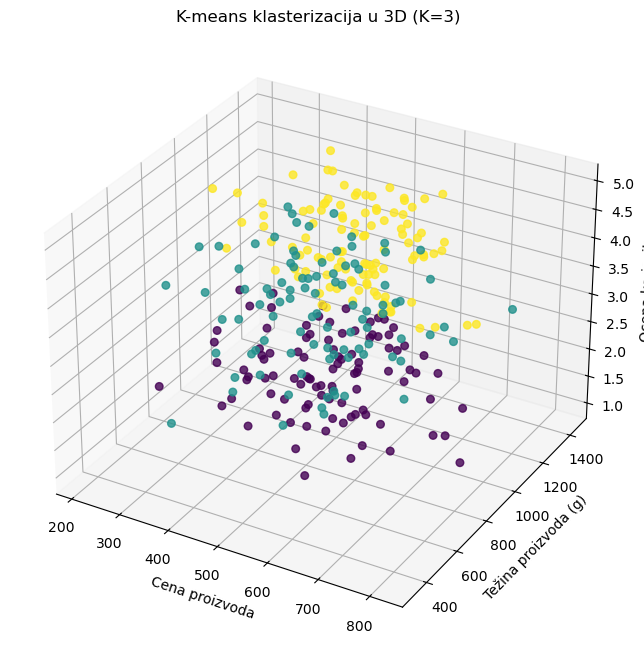

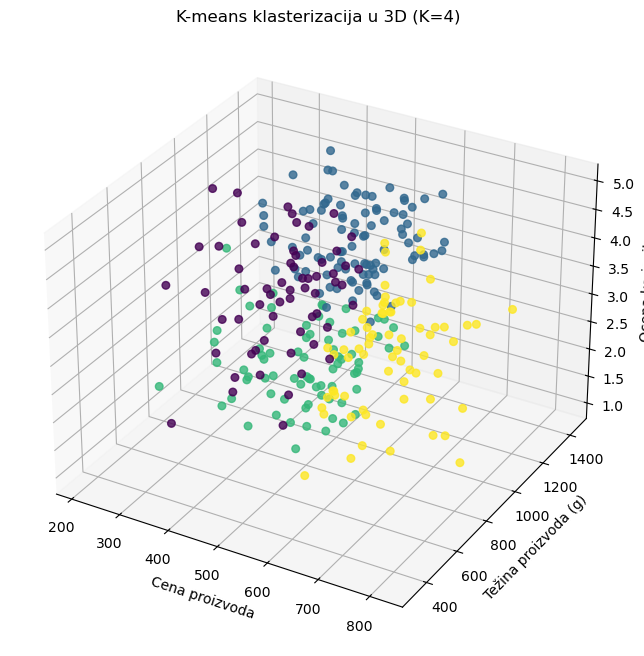

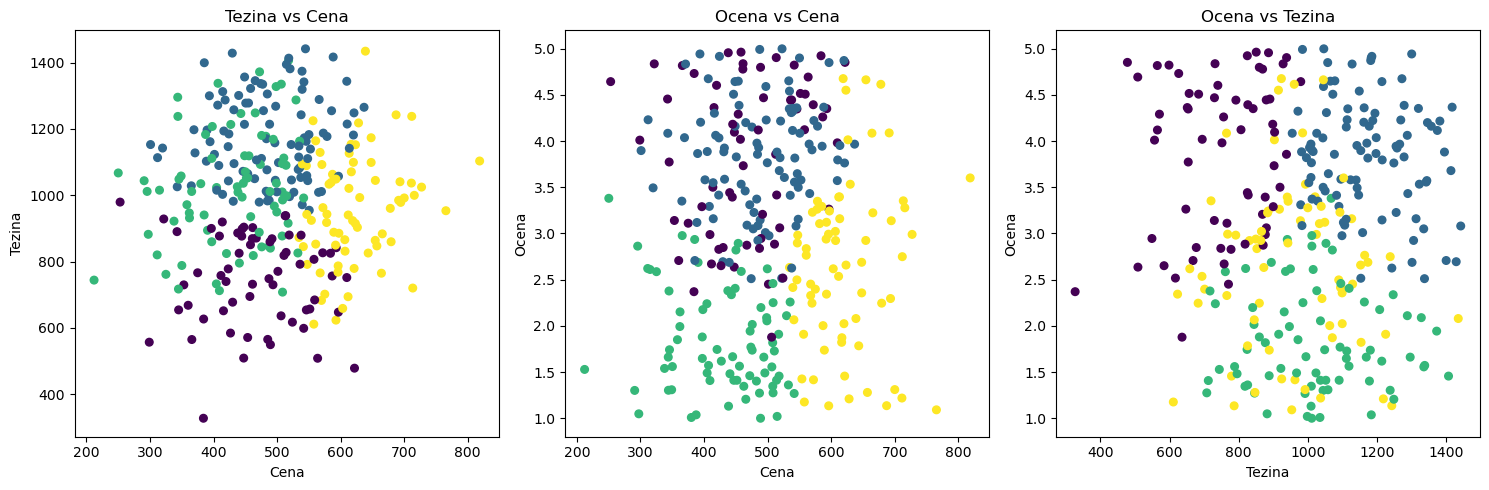

In [49]:
def visualize_results(podaci, labels_dict):
    for k in range(2, 5):
        labels = labels_dict[k]
        
        fig = plt.figure(figsize=(10, 8))
        ax = fig.add_subplot(111, projection='3d')
        
        scatter = ax.scatter(podaci[:,0], podaci[:,1], podaci[:,2],
                             c=labels, cmap='viridis', s=30, alpha=0.8)
        
        ax.set_xlabel("Cena proizvoda")
        ax.set_ylabel("Težina proizvoda (g)")
        ax.set_zlabel("Ocena korisnika")
        ax.set_title(f"K-means klasterizacija u 3D (K={k})")
        
        plt.show()
    
    
    features = ["Cena", "Tezina", "Ocena"]
    indices = [0, 1, 2]
    
    plt.figure(figsize=(15,5))
    
    plot_id = 1
    for i in range(len(indices)):
        for j in range(i+1, len(indices)):
            plt.subplot(1, 3, plot_id)
            plt.scatter(podaci[:, indices[i]], podaci[:, indices[j]], c=labels_dict[4], cmap='viridis', s=30)
            plt.xlabel(features[indices[i]])
            plt.ylabel(features[indices[j]])
            plt.title(f"{features[indices[j]]} vs {features[indices[i]]}")
            plot_id += 1
    
    plt.tight_layout()
    plt.show()

visualize_results(podaci, labels_dict)

K-means алгоритам је осетљив на редове величина у компонентама података. Скалирајте различите вредности компоненти и проверите резултате примене K-means алгоритма над трансформисаним подацима.

(5 поена)

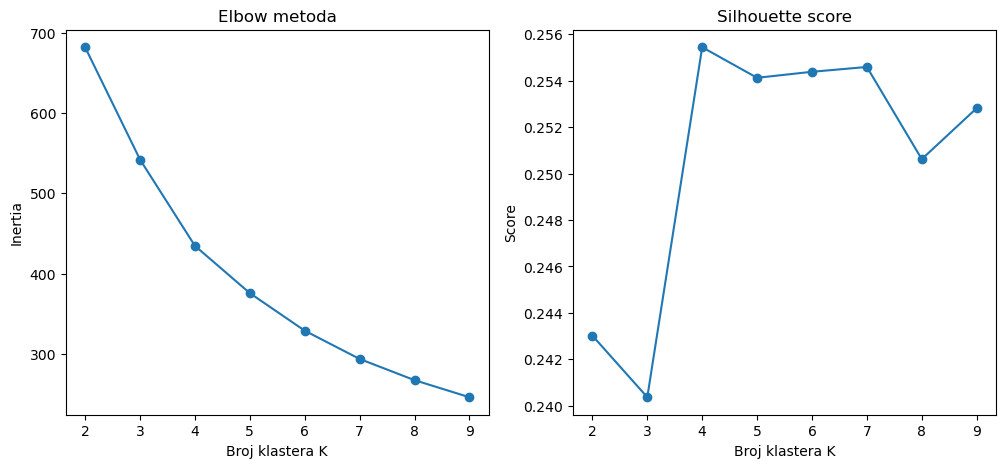

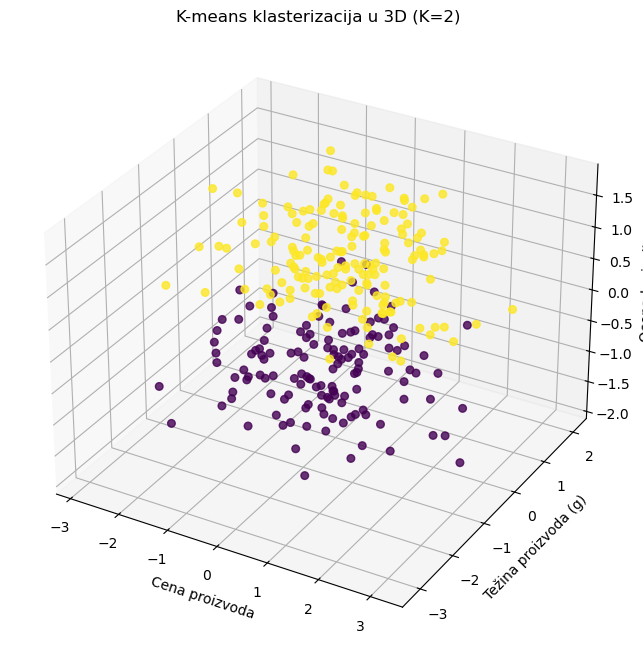

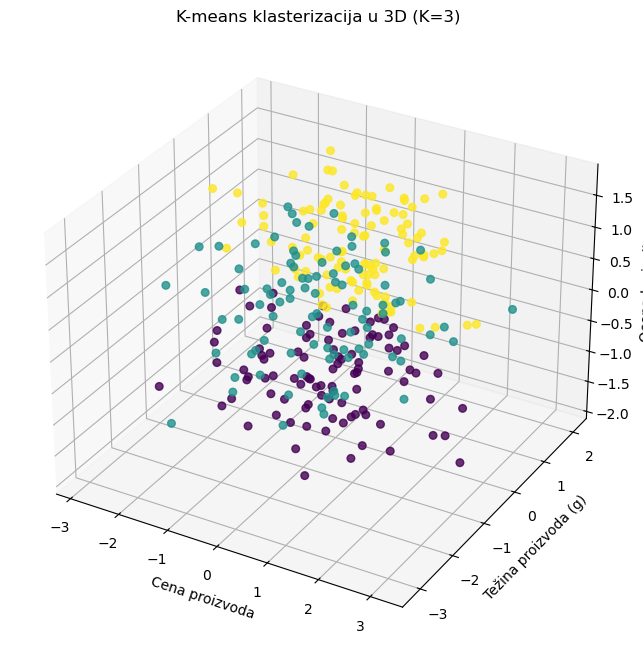

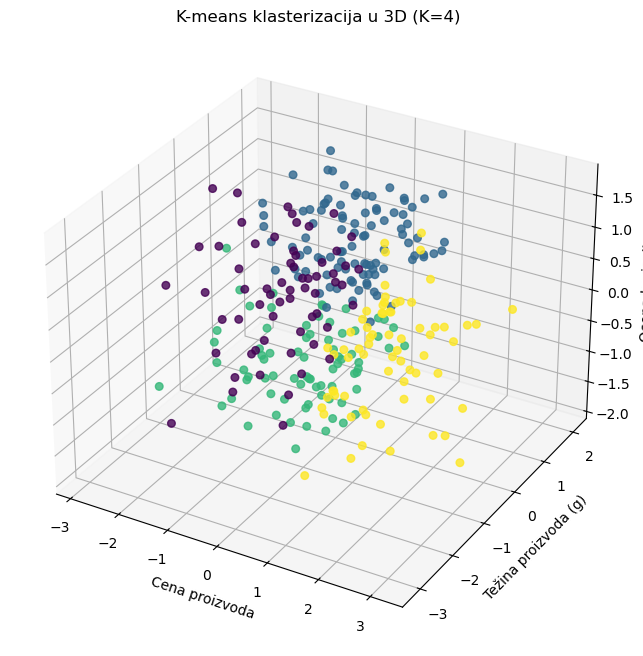

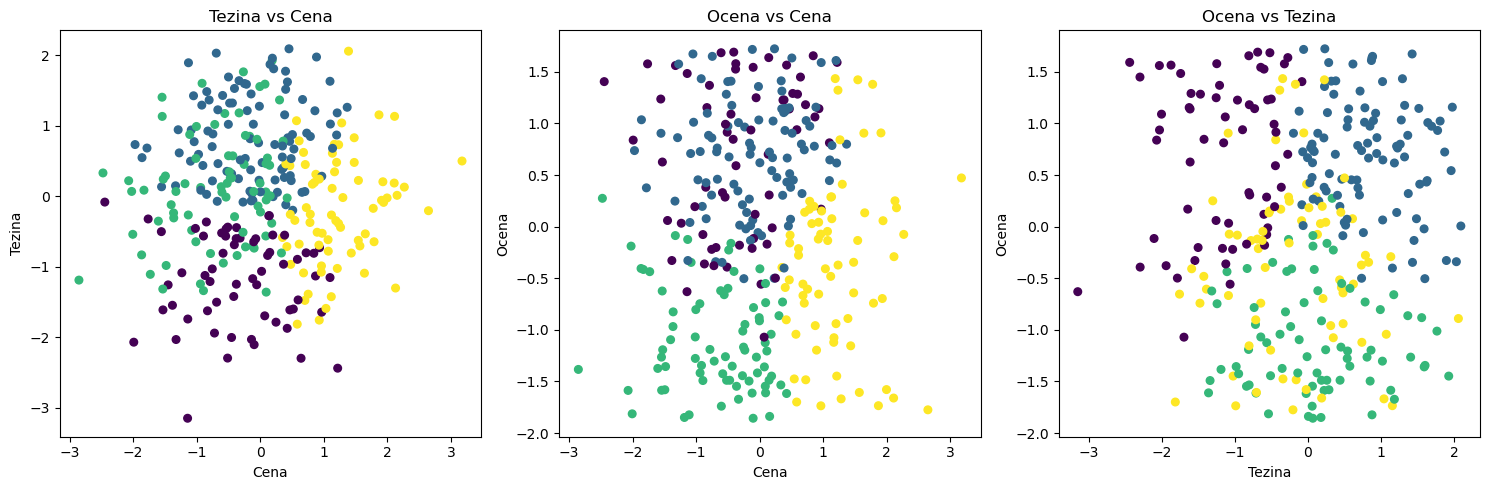

In [50]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
podaci_scaled = scaler.fit_transform(podaci)

inertias, sil_scores, K_range, labels_dict = execute_Kmeans(podaci_scaled)
draw_elbow_and_silhouette(K_range, inertias, sil_scores)
visualize_results(podaci_scaled, labels_dict)

***

**Задатак 4.** За слику учитану наредном кодном ћелијом спровести сегментацију слике у боји употребом K-means алгоритма. Одредити број кластера на основу критеријума ваљаности кластеризације обрађених у радној свесци 15K-means.

**Објашњење :** Сегментација слике је поступак поделе слике на регионе који су релативно хомогене структуре. Пример слике и сегментиране слике дат је у наставку.

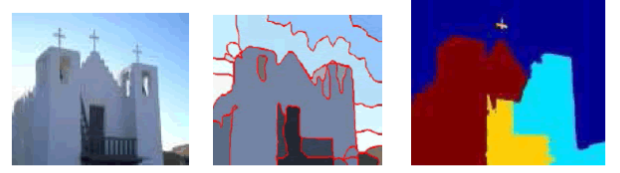

In [19]:
import scipy.datasets as scd
rakun=scd.face()
type(rakun)

numpy.ndarray

**а)** За поступак сегментације третирати сваки пиксел као вектор вредности RGB канала. Другим речима сваки пиксел је вектор тродимензионалног простора где одговарајуће компоненте означавају интензитет одговарајућег канала RGB простора слика. Упоредити добијени резултат са одговарајућом сегментацијом ако је слика дата у CIELAB простору слика. 

(5поена)

**б)** У наредном кораку сваком од пиксел-вектора (RGB и CIELAB) додати просторне координате, тј. координате положаја пиксела на слици. То је број врсте и колоне у којој се пиксел налази. На тај начин сваки пиксел постаје елемент петодимензионалног векторског простора. Спровести нову сегментацију слике употребом K-means алгоритма. 

(5 поена)

**в)** У наредном кораку скалирати све компоненте на интервал $[0,1]$ користећи информације о минимуму и максимуму дуж одговарајуће координатне осе.

(5 поена)

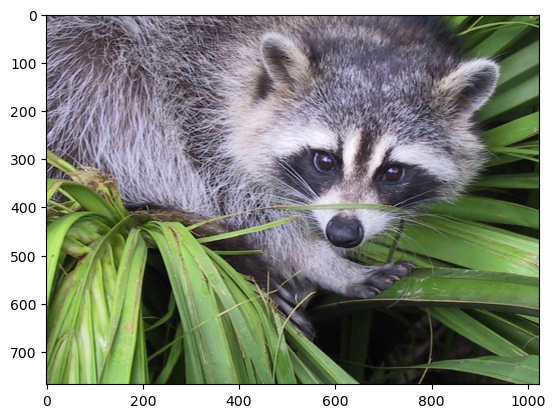

In [20]:
plt.imshow(rakun);

**г)** Искористити претходни поступак сегментације за компресију учитане слике. Сваки тродимензионални пиксел-вектор заменити центром кластера коме тај пиксел припада. 

(5 поена)

Заменом сваког пиксела центром његовог кластера вршимо компресију.  
Проблем се може посматрати као складиштење матрица.

#### Оригинални формат
$$
N_{\text{pix}} \times 3 \quad (\text{float/int})
$$


#### Компресовани формат
- Матрица индекса:  
  $$
  N_{\text{pix}} \times 1 \quad (\text{int})
  $$
- Матрица центара (Codebook):  
 $$
  K \times 3 \quad (\text{float})
  $$

**д)** Израчунати уштеду меморије и приказати однос компресије за:
$$
K \in \{2, 5, 10, 20\}.
$$

(5 поена)

***